In [1]:
from google.colab import drive
import pandas as pd
import zipfile
import os

# 1. Mount Drive
drive.mount('/content/drive')

# 2. Đường dẫn tới file ZIP trong Bộ nhớ dùng chung
zip_path = '/content/drive/Shared drives/ML/data/rossmann-store-sales.zip'

# 3. Giải nén dữ liệu vào môi trường tạm của Colab (/content/data_raw)
extract_path = '/content/data_raw'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Đã giải nén xong! Các file có sẵn:", os.listdir(extract_path))

# 4. Đọc dữ liệu bằng Pandas
train_df = pd.read_csv(f'{extract_path}/train.csv', low_memory=False)
store_df = pd.read_csv(f'{extract_path}/store.csv')

print("Train shape:", train_df.shape)
print("Store shape:", store_df.shape)

Mounted at /content/drive
Đã giải nén xong! Các file có sẵn: ['test.csv', 'store.csv', 'train.csv', 'sample_submission.csv']
Train shape: (1017209, 9)
Store shape: (1115, 10)


In [2]:
train_df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [3]:
print("--- Trùng lặp trong Train:", train_df.duplicated().sum())

print("\n--- Giá trị thiếu trong Store ---")
print(store_df.isnull().sum()[store_df.isnull().sum() > 0])

print("\n--- Kiểm tra ngày đóng cửa Sales = 0 ---")
print(train_df[train_df['Open'] == 0]['Sales'].value_counts())

--- Trùng lặp trong Train: 0

--- Giá trị thiếu trong Store ---
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64

--- Kiểm tra ngày đóng cửa Sales = 0 ---
Sales
0    172817
Name: count, dtype: int64


In [4]:
# 1. Ép kiểu Date & StateHoliday
train_df['Date'] = pd.to_datetime(train_df['Date'])
train_df['StateHoliday'] = train_df['StateHoliday'].astype(str)

# 2. Xử lý thiếu trong store.csv (Điền Median cho CompetitionDistance)
store_df['CompetitionDistance'].fillna(store_df['CompetitionDistance'].median(), inplace=True)
store_df['CompetitionOpenSinceMonth'].fillna(-1, inplace=True)
store_df['CompetitionOpenSinceYear'].fillna(-1, inplace=True)
store_df['Promo2SinceWeek'].fillna(0, inplace=True)
store_df['Promo2SinceYear'].fillna(0, inplace=True)
store_df['PromoInterval'].fillna('None', inplace=True)

# 3. Lọc bỏ các ngày cửa hàng đóng cửa (Sales = 0 và Open = 0)
train_clean = train_df[(train_df['Open'] != 0) & (train_df['Sales'] > 0)].copy()

print("Kích thước tập Train sau khi làm sạch:", train_clean.shape)

Kích thước tập Train sau khi làm sạch: (844338, 9)


/tmp/ipykernel_2333/3721506031.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  store_df['CompetitionDistance'].fillna(store_df['CompetitionDistance'].median(), inplace=True)
/tmp/ipykernel_2333/3721506031.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doi

In [5]:
## 4. Ghép bảng và tạo đặc trưng thời gian
df = train_clean.merge(store_df, on='Store', how='left')

df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)
df['DayOfWeekName'] = df['Date'].dt.day_name()

print("Shape sau khi ghép:", df.shape)
print("Khoảng thời gian:", df['Date'].min().date(), "→", df['Date'].max().date())
print("Số cửa hàng:", df['Store'].nunique())
df[['Store','Date','Sales','Customers','Promo','StoreType','Assortment','CompetitionDistance']].head()

Shape sau khi ghép: (844338, 22)
Khoảng thời gian: 2013-01-01 → 2015-07-31
Số cửa hàng: 1115


,Store,Date,Sales,Customers,Promo,StoreType,Assortment,CompetitionDistance
0,1,2015-07-31,5263,555,1,c,a,1270.0
1,2,2015-07-31,6064,625,1,a,a,570.0
2,3,2015-07-31,8314,821,1,a,a,14130.0
3,4,2015-07-31,13995,1498,1,c,c,620.0
4,5,2015-07-31,4822,559,1,a,a,29910.0


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

print(df['Sales'].describe().round(1))

count    844338.0
mean       6956.0
std        3103.8
min          46.0
25%        4859.0
50%        6369.0
75%        8360.0
max       41551.0
Name: Sales, dtype: float64


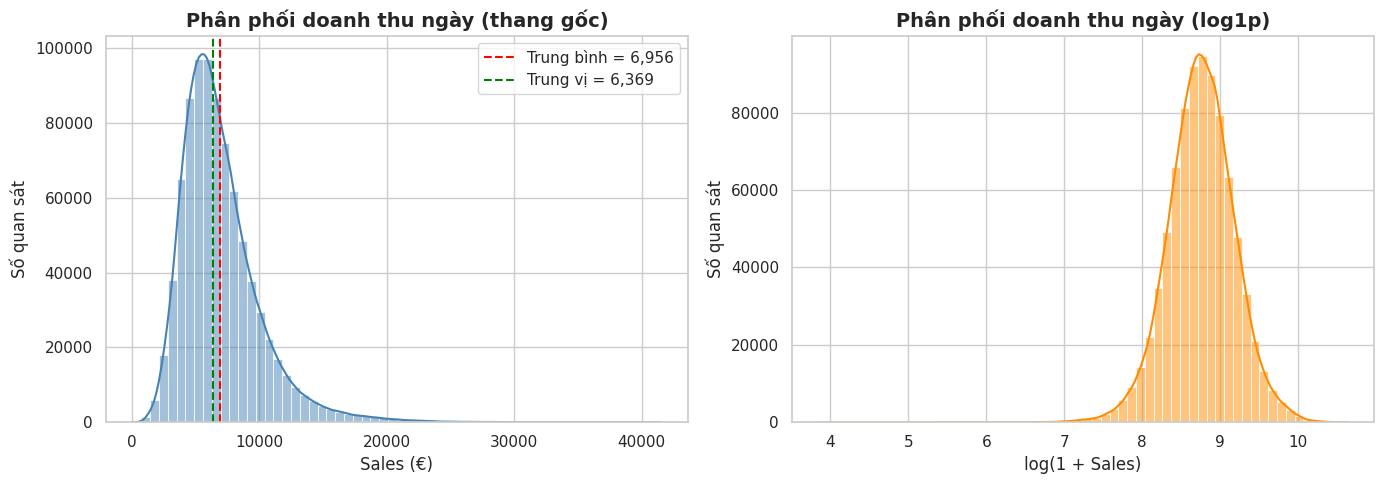

Skewness gốc: 1.59 | Skewness sau log1p: -0.11


In [7]:
### Biểu đồ 1 – Phân phối doanh thu theo ngày (`Sales`)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Sales'], bins=60, kde=True, ax=axes[0], color='steelblue')
axes[0].axvline(df['Sales'].mean(), color='red', ls='--', label=f"Trung bình = {df['Sales'].mean():,.0f}")
axes[0].axvline(df['Sales'].median(), color='green', ls='--', label=f"Trung vị = {df['Sales'].median():,.0f}")
axes[0].set_title('Phân phối doanh thu ngày (thang gốc)')
axes[0].set_xlabel('Sales (€)'); axes[0].set_ylabel('Số quan sát'); axes[0].legend()

sns.histplot(np.log1p(df['Sales']), bins=60, kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('Phân phối doanh thu ngày (log1p)')
axes[1].set_xlabel('log(1 + Sales)'); axes[1].set_ylabel('Số quan sát')

plt.tight_layout(); plt.show()
print("Skewness gốc:", round(df['Sales'].skew(), 2), "| Skewness sau log1p:", round(np.log1p(df['Sales']).skew(), 2))

/tmp/ipykernel_2333/1599603757.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dow.index, y=dow['AvgSales'], ax=ax, palette='Blues_d')


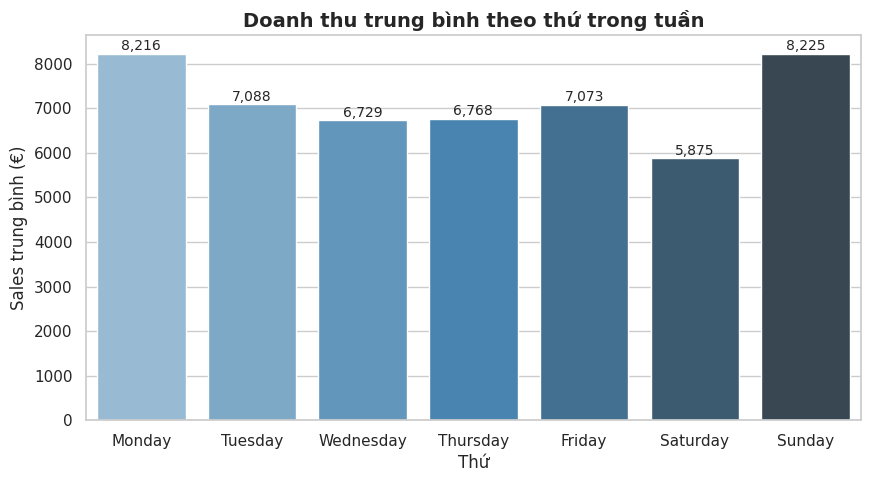

               AvgSales     Obs
DayOfWeekName                  
Monday           8216.0  137557
Tuesday          7088.0  143955
Wednesday        6729.0  141922
Thursday         6768.0  134626
Friday           7073.0  138633
Saturday         5875.0  144052
Sunday           8225.0    3593


In [8]:
### Biểu đồ 2 – Doanh thu trung bình theo thứ trong tuần
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
dow = df.groupby('DayOfWeekName').agg(AvgSales=('Sales','mean'), Obs=('Sales','size')).reindex(order)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=dow.index, y=dow['AvgSales'], ax=ax, palette='Blues_d')
for i, v in enumerate(dow['AvgSales']):
    ax.text(i, v + 80, f"{v:,.0f}", ha='center', fontsize=10)
ax.set_title('Doanh thu trung bình theo thứ trong tuần')
ax.set_xlabel('Thứ'); ax.set_ylabel('Sales trung bình (€)')
plt.show()
print(dow.round(0))

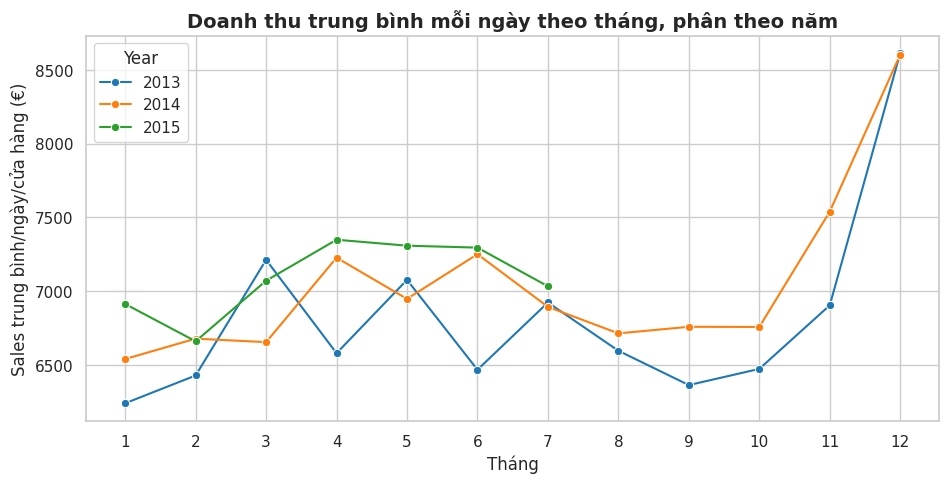

Dữ liệu 2015 chỉ đến tháng: 7


In [9]:
### Biểu đồ 3 – Xu hướng và tính mùa vụ theo tháng
monthly = df.groupby(['Year','Month'])['Sales'].mean().reset_index()

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=monthly, x='Month', y='Sales', hue='Year', marker='o', palette='tab10', ax=ax)
ax.set_xticks(range(1, 13))
ax.set_title('Doanh thu trung bình mỗi ngày theo tháng, phân theo năm')
ax.set_xlabel('Tháng'); ax.set_ylabel('Sales trung bình/ngày/cửa hàng (€)')
plt.show()
print("Dữ liệu 2015 chỉ đến tháng:", df[df['Year']==2015]['Month'].max())

/tmp/ipykernel_2333/1936491420.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Promo', y='Sales', ax=axes[0], palette='Set2', showfliers=False)
/tmp/ipykernel_2333/1936491420.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Không KM', 'Có KM'])
/tmp/ipykernel_2333/1936491420.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Không KM','Có KM'], y=promo_mean.values, ax=axes[1], palette='Set2')


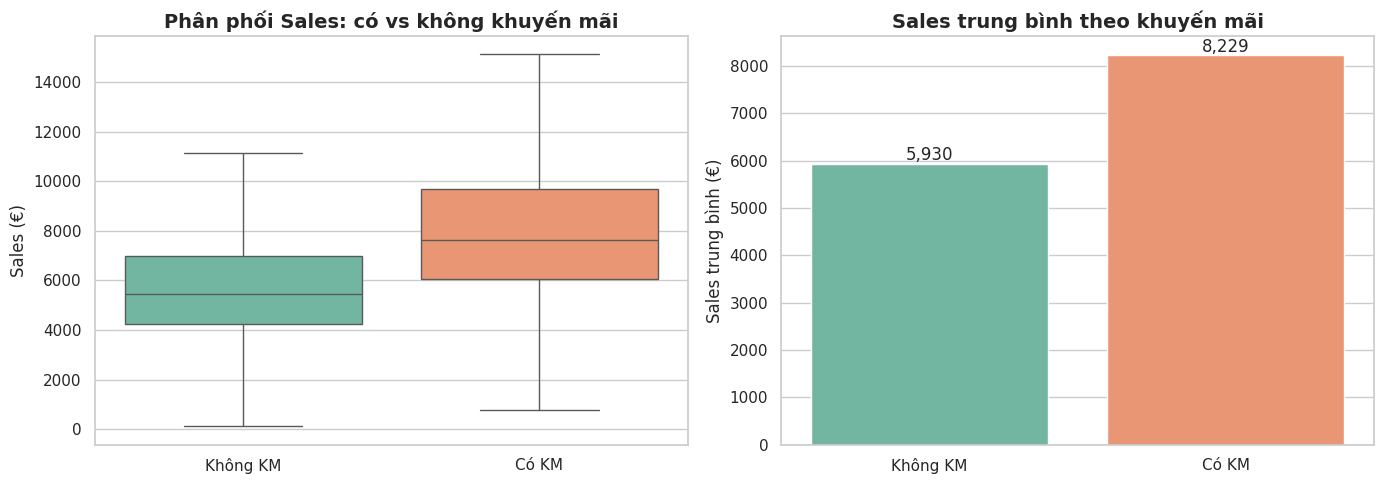

Doanh thu trung bình tăng khoảng 38.8% khi có khuyến mãi


In [10]:
### Biểu đồ 4 – Ảnh hưởng của khuyến mãi (Promo)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='Promo', y='Sales', ax=axes[0], palette='Set2', showfliers=False)
axes[0].set_xticklabels(['Không KM', 'Có KM'])
axes[0].set_title('Phân phối Sales: có vs không khuyến mãi')
axes[0].set_xlabel(''); axes[0].set_ylabel('Sales (€)')

promo_mean = df.groupby('Promo')['Sales'].mean()
sns.barplot(x=['Không KM','Có KM'], y=promo_mean.values, ax=axes[1], palette='Set2')
for i, v in enumerate(promo_mean.values):
    axes[1].text(i, v + 80, f"{v:,.0f}", ha='center')
axes[1].set_title('Sales trung bình theo khuyến mãi')
axes[1].set_ylabel('Sales trung bình (€)')
plt.tight_layout(); plt.show()

uplift = (promo_mean[1] / promo_mean[0] - 1) * 100
print(f"Doanh thu trung bình tăng khoảng {uplift:.1f}% khi có khuyến mãi")

/tmp/ipykernel_2333/804855594.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=st.index, y=st.values, ax=axes[0], palette='viridis')
/tmp/ipykernel_2333/804855594.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=asm.index, y=asm.values, ax=axes[1], palette='magma')


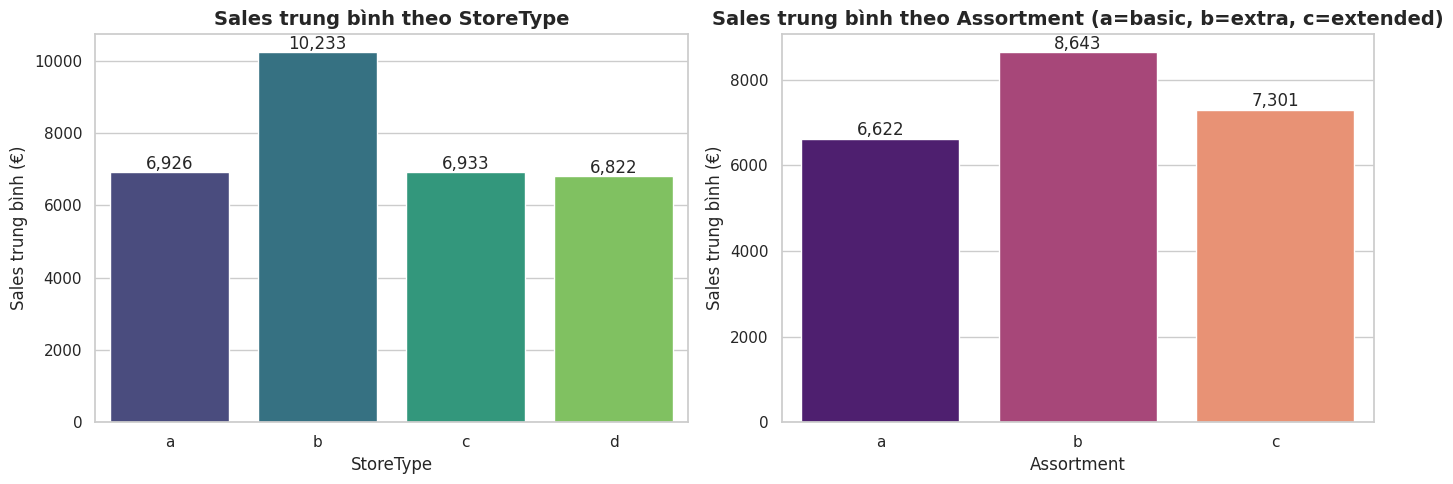

Số cửa hàng theo StoreType:
 StoreType
a    602
b     17
c    148
d    348
Name: count, dtype: int64

Số cửa hàng theo Assortment:
 Assortment
a    593
b      9
c    513
Name: count, dtype: int64


In [11]:
### Biểu đồ 5 – Doanh thu theo loại cửa hàng (`StoreType`) và danh mục hàng (`Assortment`)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

st = df.groupby('StoreType')['Sales'].mean().sort_index()
sns.barplot(x=st.index, y=st.values, ax=axes[0], palette='viridis')
for i, v in enumerate(st.values):
    axes[0].text(i, v + 80, f"{v:,.0f}", ha='center')
axes[0].set_title('Sales trung bình theo StoreType')
axes[0].set_xlabel('StoreType'); axes[0].set_ylabel('Sales trung bình (€)')

asm = df.groupby('Assortment')['Sales'].mean().sort_index()
sns.barplot(x=asm.index, y=asm.values, ax=axes[1], palette='magma')
for i, v in enumerate(asm.values):
    axes[1].text(i, v + 80, f"{v:,.0f}", ha='center')
axes[1].set_title('Sales trung bình theo Assortment (a=basic, b=extra, c=extended)')
axes[1].set_xlabel('Assortment'); axes[1].set_ylabel('Sales trung bình (€)')
plt.tight_layout(); plt.show()

print("Số cửa hàng theo StoreType:\n", store_df['StoreType'].value_counts().sort_index())
print("\nSố cửa hàng theo Assortment:\n", store_df['Assortment'].value_counts().sort_index())

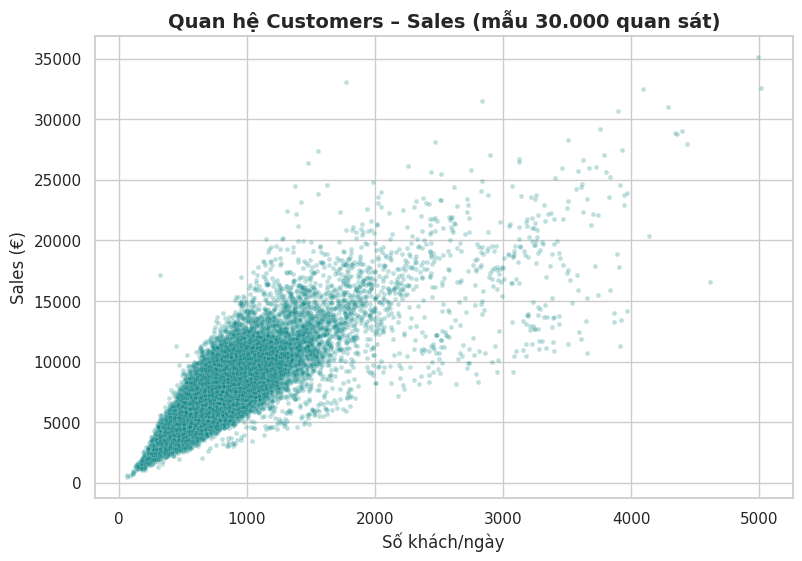

Hệ số tương quan Pearson Customers–Sales: 0.824


In [12]:
### Biểu đồ 6 – Quan hệ giữa số khách (`Customers`) và doanh thu
sample = df.sample(30000, random_state=42)

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=sample, x='Customers', y='Sales', alpha=0.25, s=12, ax=ax, color='teal')
ax.set_title('Quan hệ Customers – Sales (mẫu 30.000 quan sát)')
ax.set_xlabel('Số khách/ngày'); ax.set_ylabel('Sales (€)')
plt.show()

corr = df['Customers'].corr(df['Sales'])
print(f"Hệ số tương quan Pearson Customers–Sales: {corr:.3f}")

/tmp/ipykernel_2333/371127324.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=comp.index.astype(str), y=comp['mean'], ax=ax, palette='rocket')


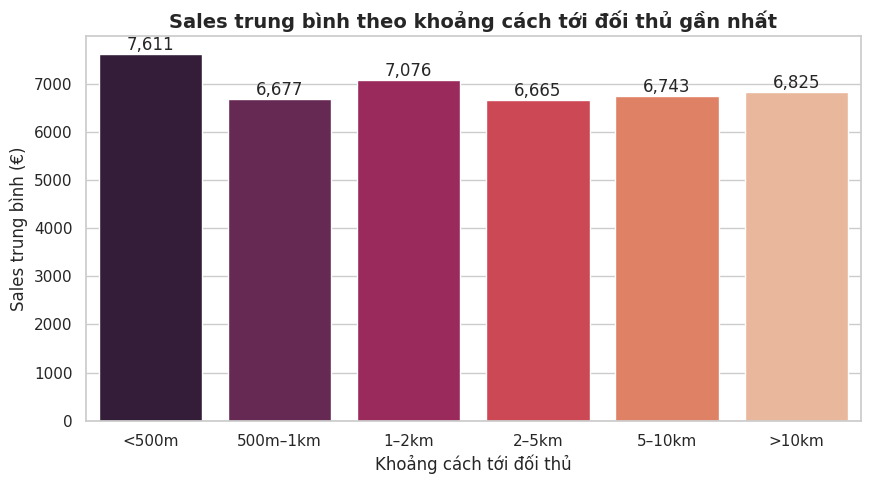

               mean    size
CompDistBin                
<500m        7611.0  168086
500m–1km     6677.0   82845
1–2km        7076.0  129834
2–5km        6665.0  199058
5–10km       6743.0  121910
>10km        6825.0  142605


In [13]:
### Biểu đồ 7 – Khoảng cách đến đối thủ (`CompetitionDistance`) và doanh thu
tmp = df.copy()
tmp['CompDistBin'] = pd.cut(tmp['CompetitionDistance'],
                            bins=[0, 500, 1000, 2000, 5000, 10000, np.inf],
                            labels=['<500m', '500m–1km', '1–2km', '2–5km', '5–10km', '>10km'])
comp = tmp.groupby('CompDistBin', observed=True)['Sales'].agg(['mean', 'size'])

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=comp.index.astype(str), y=comp['mean'], ax=ax, palette='rocket')
for i, v in enumerate(comp['mean']):
    ax.text(i, v + 80, f"{v:,.0f}", ha='center')
ax.set_title('Sales trung bình theo khoảng cách tới đối thủ gần nhất')
ax.set_xlabel('Khoảng cách tới đối thủ'); ax.set_ylabel('Sales trung bình (€)')
plt.show()
print(comp.round(0))

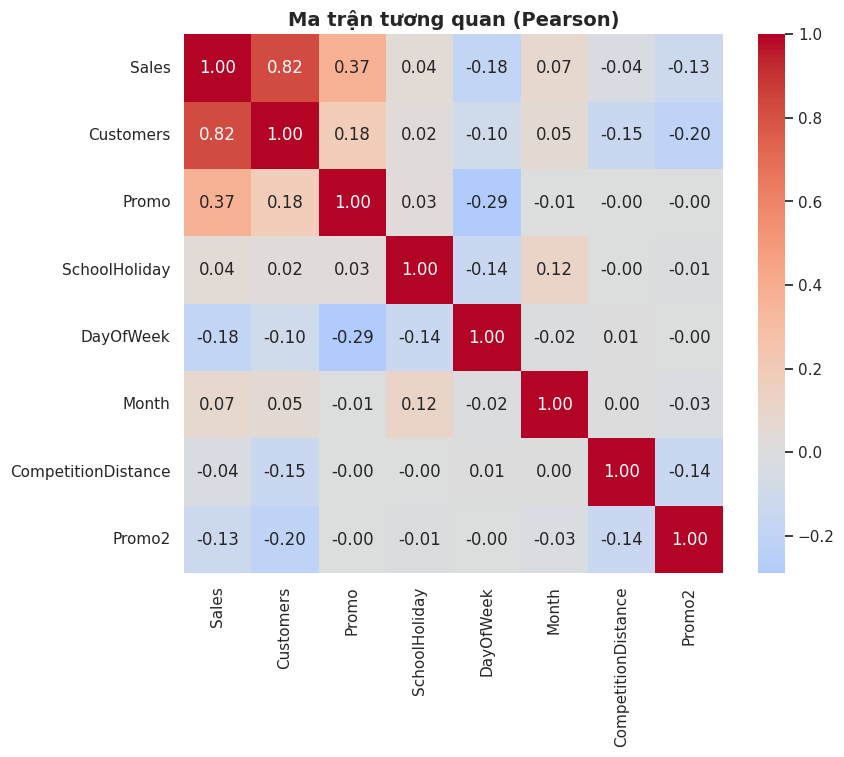

Customers              0.824
Promo                  0.368
Month                  0.074
SchoolHoliday          0.039
CompetitionDistance   -0.036
Promo2                -0.128
DayOfWeek             -0.179
Name: Sales, dtype: float64


In [14]:
### Biểu đồ 8 – Ma trận tương quan giữa các biến số
num_cols = ['Sales','Customers','Promo','SchoolHoliday','DayOfWeek','Month',
            'CompetitionDistance','Promo2']
corr_mat = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, ax=ax)
ax.set_title('Ma trận tương quan (Pearson)')
plt.show()

print(corr_mat['Sales'].drop('Sales').sort_values(ascending=False).round(3))

In [15]:
# ==============================================================================
# B5: PIPELINE TIỀN XỬ LÝ & FEATURE ENGINEERING (RossmannDataPipeline)
# Điều kiện hoàn thành: Gọi 1 LỆNH (1 hàm) ra ngay dữ liệu sạch đã được xử lý.
# ==============================================================================

import pandas as pd
import numpy as np

class RossmannDataPipeline:
    """
    Pipeline tiền xử lý & Feature Engineering tự động cho bài toán Rossmann Store Sales.
    Được thiết kế mô-đun hóa để dùng lại trực tiếp khi làm Web / API.
    """
    def __init__(self, median_competition_dist=2325.0):
        # Giá trị Median mặc định của CompetitionDistance từ tập dữ liệu
        self.median_competition_dist = median_competition_dist

    def fit(self, store_raw):
        """Học giá trị thống kê từ tập store gốc"""
        if 'CompetitionDistance' in store_raw.columns:
            self.median_competition_dist = store_raw['CompetitionDistance'].median()
        return self

    def preprocess_store(self, store_raw):
        """1. Làm sạch và bù thiếu cho bảng thuộc tính cửa hàng (store.csv)"""
        store = store_raw.copy()

        # Bù thiếu CompetitionDistance bằng Median
        store['CompetitionDistance'] = store['CompetitionDistance'].fillna(self.median_competition_dist)

        # Bù thiếu ngày/tháng mở cửa đối thủ (-1 đánh dấu chưa rõ/chưa có)
        store['CompetitionOpenSinceMonth'] = store['CompetitionOpenSinceMonth'].fillna(-1).astype(int)
        store['CompetitionOpenSinceYear'] = store['CompetitionOpenSinceYear'].fillna(-1).astype(int)

        # Bù thiếu cho nhóm Promo2
        store['Promo2SinceWeek'] = store['Promo2SinceWeek'].fillna(0).astype(int)
        store['Promo2SinceYear'] = store['Promo2SinceYear'].fillna(0).astype(int)
        store['PromoInterval'] = store['PromoInterval'].fillna('None')

        # Feature cờ hiệu có đối thủ cạnh tranh hay không
        store['HasCompetition'] = (store['CompetitionOpenSinceYear'] != -1).astype(int)

        return store

    def preprocess_train(self, train_raw, is_train_set=True):
        """2. Làm sạch bảng giao dịch (train.csv / test.csv)"""
        df = train_raw.copy()

        # Ép kiểu Date
        df['Date'] = pd.to_datetime(df['Date'])

        # Chuẩn hóa StateHoliday về dạng chuỗi thống nhất ('0', 'a', 'b', 'c')
        df['StateHoliday'] = df['StateHoliday'].astype(str).replace({'0.0': '0', '0': '0'})

        # Lọc nhiễu: Bỏ các ngày đóng cửa (Open=0) hoặc doanh thu Sales <= 0 (chỉ áp dụng khi huấn luyện)
        if is_train_set:
            if 'Open' in df.columns and 'Sales' in df.columns:
                df = df[(df['Open'] != 0) & (df['Sales'] > 0)].copy()

        return df

    def feature_engineering(self, df):
        """3. Tạo các đặc trưng mới (Thời gian, Ngày lễ, Tương tác Phục vụ What-If Scenario)"""
        data = df.copy()

        # A. Đặc trưng thời gian (Temporal Features)
        data['Year'] = data['Date'].dt.year
        data['Month'] = data['Date'].dt.month
        data['Day'] = data['Date'].dt.day
        data['WeekOfYear'] = data['Date'].dt.isocalendar().week.astype(int)
        data['DayOfWeek'] = data['Date'].dt.dayofweek + 1  # 1: Thứ Hai -> 7: Chủ Nhật
        data['IsWeekend'] = (data['DayOfWeek'] >= 6).astype(int)
        data['IsMonthStart'] = data['Date'].dt.is_month_start.astype(int)
        data['IsMonthEnd'] = data['Date'].dt.is_month_end.astype(int)

        # B. Biến đổi Log cho Sales (Nếu có cột Sales để hỗ trợ mô hình Regression)
        if 'Sales' in data.columns:
            data['LogSales'] = np.log1p(data['Sales'])

        # C. Đặc trưng ngày lễ
        data['IsStateHoliday'] = (data['StateHoliday'] != '0').astype(int)

        # D. Đặc trưng phục vụ tính năng "What-If Scenario Analysis" (Khuyến mãi x Ngày lễ)
        data['Promo_x_SchoolHoliday'] = data['Promo'] * data['SchoolHoliday']
        data['Promo_x_StateHoliday'] = data['Promo'] * data['IsStateHoliday']

        return data

    def transform(self, train_raw, store_raw, is_train_set=True):
        """
        [ĐIỀU KIỆN HOÀN THÀNH B5] Gọi 1 lệnh duy nhất làm sạch, nối bảng và tạo đặc trưng!
        """
        clean_store = self.preprocess_store(store_raw)
        clean_train = self.preprocess_train(train_raw, is_train_set=is_train_set)

        # Merge 2 bảng qua khóa Store
        merged_df = pd.merge(clean_train, clean_store, on='Store', how='left')

        # Tạo Feature Engineering
        final_df = self.feature_engineering(merged_df)

        # Sắp xếp lại theo thời gian
        final_df = final_df.sort_values(by=['Date', 'Store']).reset_index(drop=True)

        return final_df


# ==============================================================================
# BƯỚC THỬ NGHIỆM TẠI CHỖ (DEMO 1 LỆNH)
# ==============================================================================
# 1. Khởi tạo Pipeline
pipeline = RossmannDataPipeline()

# 2. CHẠY 1 LỆNH DUY NHẤT RA DỮ LIỆU SẠCH TỔNG HỢP (train_df, store_df đã đọc ở ô trước đó)
df_clean_pipeline = pipeline.transform(train_df, store_df, is_train_set=True)

print("✅ NGHIỆM THU B5 THÀNH CÔNG!")
print("Kích thước dữ liệu sạch hoàn chỉnh:", df_clean_pipeline.shape)
print("\nDanh sách các cột dữ liệu mới phục vụ ML & Web:")
print(df_clean_pipeline.columns.tolist())

✅ NGHIỆM THU B5 THÀNH CÔNG!
Kích thước dữ liệu sạch hoàn chỉnh: (844338, 30)

Danh sách các cột dữ liệu mới phục vụ ML & Web:
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'HasCompetition', 'Year', 'Month', 'Day', 'WeekOfYear', 'IsWeekend', 'IsMonthStart', 'IsMonthEnd', 'LogSales', 'IsStateHoliday', 'Promo_x_SchoolHoliday', 'Promo_x_StateHoliday']


In [16]:
import random
import numpy as np
import pandas as pd

from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error

# --- 0. CỐ ĐỊNH SEED TOÀN CỤC ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# --- 1. CHIA TẬP TRAIN / VAL / TEST HOLDOUT THEO THỜI GIAN ---
d = df_clean_pipeline.copy()

# Đảm bảo cột Date có kiểu datetime
d['Date'] = pd.to_datetime(d['Date'])

train_split = d[d['Date'] <= '2015-05-07'].copy()

val_split = d[
    (d['Date'] >= '2015-05-08') &
    (d['Date'] <= '2015-06-18')
].copy()

test_split = d[d['Date'] >= '2015-06-19'].copy()

# --- 2. LỰA CHỌN ĐẶC TRƯNG ---
features = [
    'Store', 'DayOfWeek', 'Promo', 'SchoolHoliday', 'HasCompetition',
    'CompetitionDistance', 'CompetitionOpenSinceMonth',
    'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
    'Promo2SinceYear', 'Year', 'Month', 'Day', 'WeekOfYear',
    'IsWeekend', 'IsMonthStart', 'IsMonthEnd', 'IsStateHoliday',
    'Promo_x_SchoolHoliday', 'Promo_x_StateHoliday',
    'StoreType', 'Assortment', 'PromoInterval'
]

categorical_cols = [
    'StoreType', 'Assortment', 'PromoInterval'
]

# Kiểm tra các cột cần thiết
required_cols = features + ['LogSales', 'Sales', 'Date']
missing_cols = [
    col for col in required_cols
    if col not in d.columns
]

if missing_cols:
    raise ValueError(
        f"Thiếu các cột trong df_clean_pipeline: {missing_cols}"
    )

# --- TẠO X VÀ y ---
X_train = train_split[features].copy()
y_train_log = train_split['LogSales'].copy()

X_val = val_split[features].copy()
y_val_log = val_split['LogSales'].copy()
y_val_real = val_split['Sales'].values

X_test = test_split[features].copy()
y_test_real = test_split['Sales'].values

# --- 3. MÃ HÓA BIẾN PHÂN LOẠI ---
# Fit encoder trên Train, xử lý được category mới ở Val/Test
encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X_train[categorical_cols] = encoder.fit_transform(
    X_train[categorical_cols].astype(str)
)

X_val[categorical_cols] = encoder.transform(
    X_val[categorical_cols].astype(str)
)

X_test[categorical_cols] = encoder.transform(
    X_test[categorical_cols].astype(str)
)

# --- 4. ĐỊNH NGHĨA METRICS ---
def rmspe(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mask = y_true != 0

    if not np.any(mask):
        return np.nan

    return np.sqrt(
        np.mean(
            np.square(
                (y_true[mask] - y_pred[mask]) / y_true[mask]
            )
        )
    )


def evaluate_predictions(y_true, y_pred):
    return {
        'RMSPE': rmspe(y_true, y_pred),
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred))
    }


# --- 5. BASELINE A: TRUNG BÌNH THEO STORE, DAYOFWEEK, PROMO ---
base_a = (
    train_split
    .groupby(['Store', 'DayOfWeek', 'Promo'])['Sales']
    .mean()
    .rename('pred')
    .reset_index()
)


def eval_base_a(split):
    m = split.merge(
        base_a,
        on=['Store', 'DayOfWeek', 'Promo'],
        how='left'
    )

    m['pred'] = m['pred'].fillna(
        train_split['Sales'].mean()
    )

    return evaluate_predictions(
        m['Sales'].values,
        m['pred'].values
    )


# --- 6. BASELINE B: SEASONAL NAIVE, CÙNG THỨ 52 TUẦN TRƯỚC ---
def eval_seasonal_naive(split, full):
    lag = full[['Store', 'Date', 'Sales']].copy()

    lag['Date'] = lag['Date'] + pd.Timedelta(weeks=52)

    m = split.merge(
        lag.rename(columns={'Sales': 'pred'}),
        on=['Store', 'Date'],
        how='left'
    )

    m_fill = m.merge(
        base_a,
        on=['Store', 'DayOfWeek', 'Promo'],
        how='left',
        suffixes=('', '_base')
    )

    m['pred'] = (
        m['pred']
        .fillna(m_fill['pred_base'])
        .fillna(train_split['Sales'].mean())
    )

    return evaluate_predictions(
        m['Sales'].values,
        m['pred'].values
    )


# --- 7. ĐÁNH GIÁ BASELINE ---
val_base_a_metrics = eval_base_a(val_split)
test_base_a_metrics = eval_base_a(test_split)

val_base_b_metrics = eval_seasonal_naive(val_split, d)
test_base_b_metrics = eval_seasonal_naive(test_split, d)

# --- 8. IN KẾT QUẢ ---
print(f"Tập Train: {X_train.shape}")
print(f"Tập Validation: {X_val.shape}")
print(f"Tập Test: {X_test.shape}")

print(
    f"\n[Baseline A] "
    f"Val RMSPE: {val_base_a_metrics['RMSPE']:.5f} | "
    f"Test RMSPE: {test_base_a_metrics['RMSPE']:.5f}"
)

print(
    f"[Baseline B] "
    f"Val RMSPE: {val_base_b_metrics['RMSPE']:.5f} | "
    f"Test RMSPE: {test_base_b_metrics['RMSPE']:.5f}"
)

Tập Train: (765470, 24)
Tập Validation: (37472, 24)
Tập Test: (41396, 24)

[Baseline A] Val RMSPE: 0.15309 | Test RMSPE: 0.14752
[Baseline B] Val RMSPE: 0.17340 | Test RMSPE: 0.16314


## C2: HUẤN LUYỆN MÔ HÌNH (MODEL TRAINING & COMPARISON)


In [17]:
# --- RETRAIN TRÊN TOÀN BỘ DỮ LIỆU SẠCH ---
print(
    "--- BẮT ĐẦU RETRAIN TRÊN TOÀN BỘ "
    "DỮ LIỆU SẠCH (train_df + store_df) ---"
)

import xgboost as xgb
import numpy as np
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder

# --- 1. ĐỌC DỮ LIỆU TEST THỰC TẾ ---
test_raw = pd.read_csv(
    f'{extract_path}/test.csv',
    low_memory=False
)

# Bù giá trị thiếu ở cột Open
test_raw['Open'] = test_raw['Open'].fillna(1)

# --- 2. ÁP DỤNG PIPELINE ---
# Yêu cầu pipeline và train_df, store_df đã được khởi tạo
df_full_train = pipeline.transform(
    train_df,
    store_df,
    is_train_set=True
)

df_full_test = pipeline.transform(
    test_raw,
    store_df,
    is_train_set=False
)

# --- 3. CHUẨN BỊ ĐẶC TRƯNG ---
X_full_train = df_full_train[features].copy()
y_full_train_log = df_full_train['LogSales'].copy()

X_full_test = df_full_test[features].copy()

# --- 4. MÃ HÓA CATEGORICAL ---
# Fit trên toàn bộ Train, chỉ transform Test
encoder_full = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X_full_train[categorical_cols] = encoder_full.fit_transform(
    X_full_train[categorical_cols].astype(str)
)

X_full_test[categorical_cols] = encoder_full.transform(
    X_full_test[categorical_cols].astype(str)
)

# --- 5. KIỂM TRA DỮ LIỆU ---
if X_full_train.isnull().any().any():
    print("Cảnh báo: X_full_train còn giá trị thiếu.")

if X_full_test.isnull().any().any():
    print("Cảnh báo: X_full_test còn giá trị thiếu.")

if list(X_full_train.columns) != list(X_full_test.columns):
    raise ValueError(
        "Các đặc trưng của Train và Test không đồng nhất."
    )

print(f"Train shape: {X_full_train.shape}")
print(f"Test shape: {X_full_test.shape}")

# --- 6. HUẤN LUYỆN XGBOOST ---
print("Đang huấn luyện lại XGBoost trên toàn bộ dữ liệu...")

# Khởi tạo tham số cục bộ để tránh lỗi thứ tự chạy ô trong notebook
retrain_xgb_params = {
    'objective': 'reg:squarederror',
    'learning_rate': 0.1,
    'max_depth': 7,
    'subsample': 0.9,
    'colsample_bytree': 0.9,
    'random_state': SEED,
    'n_jobs': -1
}

final_model = xgb.XGBRegressor(
    **retrain_xgb_params,
    n_estimators=400
)

final_model.fit(
    X_full_train,
    y_full_train_log
)

# --- 7. DỰ ĐOÁN DOANH THU ---
full_test_preds_log = final_model.predict(X_full_test)

# Chuyển từ log(Sales + 1) về Sales
full_test_preds = np.expm1(full_test_preds_log)

# Rossmann Sales không âm
full_test_preds = np.maximum(full_test_preds, 0)

# --- 8. TẠO FILE SUBMISSION ---
submission = pd.DataFrame({
    'Id': test_raw['Id'].astype(int),
    'Sales': full_test_preds
})

# Nếu cửa hàng đóng cửa, doanh thu bằng 0
submission.loc[test_raw['Open'] == 0, 'Sales'] = 0

# Xuất file
submission.to_csv('submission.csv', index=False)

print("\nĐã hoàn thành huấn luyện và xuất submission.csv!")
display(submission.head())
print(f"Số dòng submission: {len(submission)}")

--- BẮT ĐẦU RETRAIN TRÊN TOÀN BỘ DỮ LIỆU SẠCH (train_df + store_df) ---
Train shape: (844338, 24)
Test shape: (41088, 24)
Đang huấn luyện lại XGBoost trên toàn bộ dữ liệu...

Đã hoàn thành huấn luyện và xuất submission.csv!


,Id,Sales
0,1,4780.366699
1,2,4715.418945
2,3,7428.775391
3,4,3653.715332
4,5,6260.536133


Số dòng submission: 41088


### 1. Mô hình 1: LightGBM Regressor (Cố định Seed)

In [18]:
import lightgbm as lgb

# Định nghĩa tham số LightGBM với seed cố định
lgb_params = {
    'objective': 'regression',
    'metric': 'rmse',
    'learning_rate': 0.1,
    'max_depth': 8,
    'num_leaves': 63,
    'seed': SEED,
    'verbose': -1
}

print("Đang huấn luyện LightGBM...")
lgb_train_data = lgb.Dataset(X_train, label=y_train_log)
lgbm_model = lgb.train(
    lgb_params,
    lgb_train_data,
    num_boost_round=400
)

# Dự báo trên tập Val và Test
lgb_val_preds = np.expm1(lgbm_model.predict(X_val))
lgb_test_preds = np.expm1(lgbm_model.predict(X_test))

lgb_val_eval = evaluate_predictions(y_val_real, lgb_val_preds)
lgb_test_eval = evaluate_predictions(y_test_real, lgb_test_preds)

print(f"LightGBM Validation RMSPE: {lgb_val_eval['RMSPE']:.5f} | Test RMSPE: {lgb_test_eval['RMSPE']:.5f}")

Đang huấn luyện LightGBM...
LightGBM Validation RMSPE: 0.14662 | Test RMSPE: 0.15899


### 2. Mô hình 2: XGBoost Regressor (Cố định Seed)

In [19]:
import xgboost as xgb

xgb_params = {
    'objective': 'reg:squarederror',
    'learning_rate': 0.1,
    'max_depth': 7,
    'subsample': 0.9,
    'colsample_bytree': 0.9,
    'random_state': SEED,
    'n_jobs': -1
}

print("Đang huấn luyện XGBoost...")
xgb_reg = xgb.XGBRegressor(**xgb_params, n_estimators=400)
xgb_reg.fit(X_train, y_train_log)

# Dự báo trên tập Val và Test
xgb_val_preds = np.expm1(xgb_reg.predict(X_val))
xgb_test_preds = np.expm1(xgb_reg.predict(X_test))

xgb_val_eval = evaluate_predictions(y_val_real, xgb_val_preds)
xgb_test_eval = evaluate_predictions(y_test_real, xgb_test_preds)

print(f"XGBoost Validation RMSPE: {xgb_val_eval['RMSPE']:.5f} | Test RMSPE: {xgb_test_eval['RMSPE']:.5f}")

Đang huấn luyện XGBoost...
XGBoost Validation RMSPE: 0.14032 | Test RMSPE: 0.14849


### 3. Mô hình 3: Decision Tree Regressor (Cố định Seed)

In [20]:
from sklearn.ensemble import RandomForestRegressor

# Huấn luyện Random Forest thay thế cho Decision Tree
# Do tập dữ liệu rất lớn, sử dụng n_estimators=50 và max_samples=0.1 để đảm bảo tốc độ và tránh tràn RAM
rf_params = {
    'n_estimators': 50,
    'max_depth': 15,
    'min_samples_leaf': 10,
    'max_samples': 0.1,
    'random_state': SEED,
    'n_jobs': -1
}

print("Đang huấn luyện Random Forest...")
rf_reg = RandomForestRegressor(**rf_params)
rf_reg.fit(X_train, y_train_log)

# Dự báo trên tập Val và Test
rf_val_preds = np.expm1(rf_reg.predict(X_val))
rf_test_preds = np.expm1(rf_reg.predict(X_test))

rf_val_eval = evaluate_predictions(y_val_real, rf_val_preds)
rf_test_eval = evaluate_predictions(y_test_real, rf_test_preds)

print(f"Random Forest Validation RMSPE: {rf_val_eval['RMSPE']:.5f} | Test RMSPE: {rf_test_eval['RMSPE']:.5f}")

Đang huấn luyện Random Forest...
Random Forest Validation RMSPE: 0.21335 | Test RMSPE: 0.21300


In [21]:
# Tổng hợp bảng so sánh mô hình bao gồm cả 2 Baseline và 3 chỉ số MAE, RMSE, RMSPE
comparison_df = pd.DataFrame({
    'Mô hình': [
        'Baseline A (Store-DOW-Promo)',
        'Baseline B (Seasonal Naive)',
        'LightGBM',
        'XGBoost',
        'Random Forest'
    ],
    'Val RMSPE': [
        val_base_a_metrics['RMSPE'],
        val_base_b_metrics['RMSPE'],
        lgb_val_eval['RMSPE'],
        xgb_val_eval['RMSPE'],
        rf_val_eval['RMSPE']
    ],
    'Val MAE': [
        val_base_a_metrics['MAE'],
        val_base_b_metrics['MAE'],
        lgb_val_eval['MAE'],
        xgb_val_eval['MAE'],
        rf_val_eval['MAE']
    ],
    'Val RMSE': [
        val_base_a_metrics['RMSE'],
        val_base_b_metrics['RMSE'],
        lgb_val_eval['RMSE'],
        xgb_val_eval['RMSE'],
        rf_val_eval['RMSE']
    ],
    'Test RMSPE': [
        test_base_a_metrics['RMSPE'],
        test_base_b_metrics['RMSPE'],
        lgb_test_eval['RMSPE'],
        xgb_test_eval['RMSPE'],
        rf_test_eval['RMSPE']
    ],
    'Test MAE': [
        test_base_a_metrics['MAE'],
        test_base_b_metrics['MAE'],
        lgb_test_eval['MAE'],
        xgb_test_eval['MAE'],
        rf_test_eval['MAE']
    ],
    'Test RMSE': [
        test_base_a_metrics['RMSE'],
        test_base_b_metrics['RMSE'],
        lgb_test_eval['RMSE'],
        xgb_test_eval['RMSE'],
        rf_test_eval['RMSE']
    ]
})

display(comparison_df.style.highlight_min(subset=['Test RMSPE', 'Test MAE', 'Test RMSE'], color='lightgreen'))

,Mô hình,Val RMSPE,Val MAE,Val RMSE,Test RMSPE,Test MAE,Test RMSE
0,Baseline A (Store-DOW-Promo),0.153089,787.283372,1103.947640,0.147522,749.489178,1115.324997
1,Baseline B (Seasonal Naive),0.173401,876.404453,1243.804605,0.163136,803.667901,1210.126477
2,LightGBM,0.146618,805.328264,1126.674884,0.158991,770.491761,1123.474403
3,XGBoost,0.140323,771.729004,1079.098466,0.148490,717.662781,1041.783447
4,Random Forest,0.213354,1213.842342,1745.955904,0.213003,1099.457128,1634.950257


,Mô hình,Val RMSPE,Val MAE,Val RMSE,Test RMSPE,Test MAE,Test RMSE
0,Baseline A (Store-DOW-Promo),0.153100,787.283400,1103.947600,0.147500,749.489200,1115.325000
1,Baseline B (Seasonal Naive),0.173400,876.404500,1243.804600,0.163100,803.667900,1210.126500
2,LightGBM,0.146600,805.328300,1126.674900,0.159000,770.491800,1123.474400
3,XGBoost,0.140300,771.729000,1079.098500,0.148500,717.662800,1041.783400
4,Random Forest,0.213400,1213.842300,1745.955900,0.213000,1099.457100,1634.950300


>> Mô hình tốt nhất: XGBoost


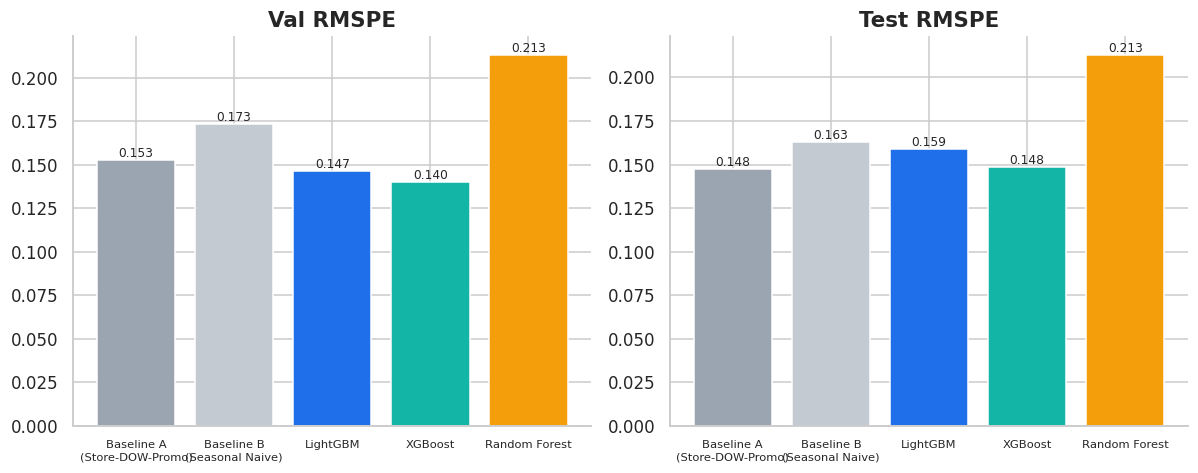

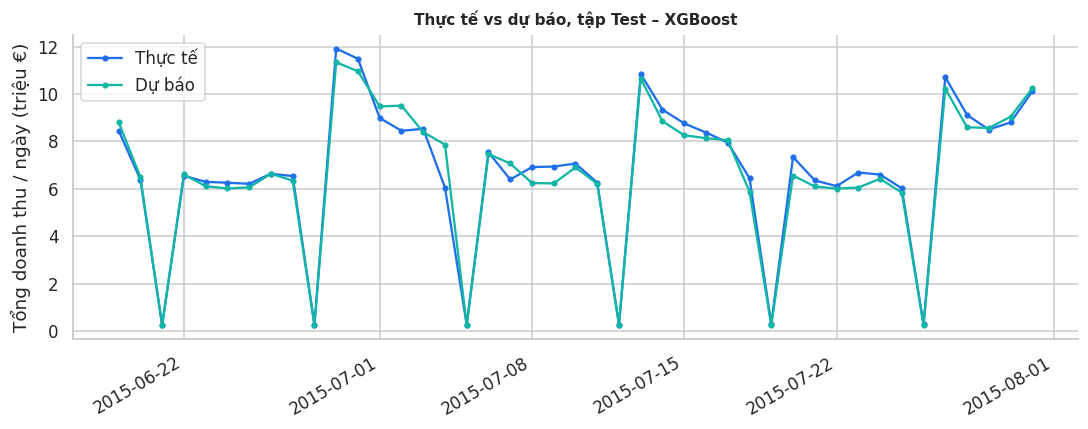

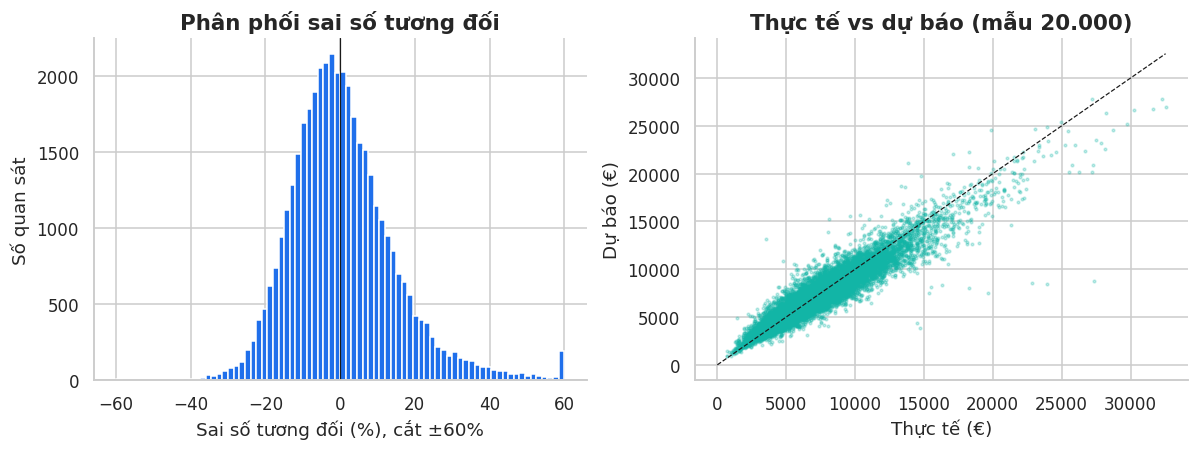

/tmp/ipykernel_2333/2916228924.py:82: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  g = res.groupby(col, observed=True).apply(seg).reset_index()
/tmp/ipykernel_2333/2916228924.py:82: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  g = res.groupby(col, observed=True).apply(seg).reset_index()
/tmp/ipykernel_2333/2916228924.py:82: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This 

--- Bảng 3: theo thứ trong tuần


/tmp/ipykernel_2333/2916228924.py:85: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  e_store = (res.groupby('Store').apply(lambda x: pd.concat([seg(x), pd.Series({'MeanSales': x['Sales'].mean()})]))


,DayOfWeek,n,RMSPE,MAE,Bias_%
0,1,6682.0,0.1269,803.2086,-1.6567
1,2,6682.0,0.1292,718.8961,-0.2962
2,3,6682.0,0.1269,638.9336,-0.6461
3,4,6680.0,0.1365,713.6894,0.0319
4,5,7795.0,0.1278,607.3433,1.6382
5,6,6682.0,0.2216,831.1412,6.3280
6,7,193.0,0.1796,1103.3139,-7.2884


--- Bảng 4: theo Promo / StoreType / Assortment / khoảng cách đối thủ


,Promo,n,RMSPE,MAE,Bias_%
0,0,23581.0,0.1614,656.3207,0.5980
1,1,17815.0,0.1294,798.8590,1.2569


... (2 outputs left out)

,CompBin,n,RMSPE,MAE,Bias_%
0,<1km,12270.0,0.1528,747.6858,1.8477
1,1-5km,16160.0,0.1527,713.2694,0.7855
2,5-20km,10816.0,0.1384,686.2100,0.0530
3,>20km,2150.0,0.1397,737.5747,0.2582


--- Bảng 5: 5 cửa hàng RMSPE cao nhất


,Store,n,RMSPE,MAE,Bias_%,MeanSales
291,292,19.0,1.158,3393.354,37.804,7261.368
908,909,23.0,0.776,7405.549,-7.323,15655.174
781,782,37.0,0.487,753.567,13.471,5347.730
875,876,23.0,0.457,4022.280,-2.282,11198.087
285,286,37.0,0.379,1029.162,32.889,3687.757


Bias tổng: +0.88% | Quan sát sai số >10%: 41.9% | Top-10 cửa hàng chiếm 8.9% tổng bình phương sai số


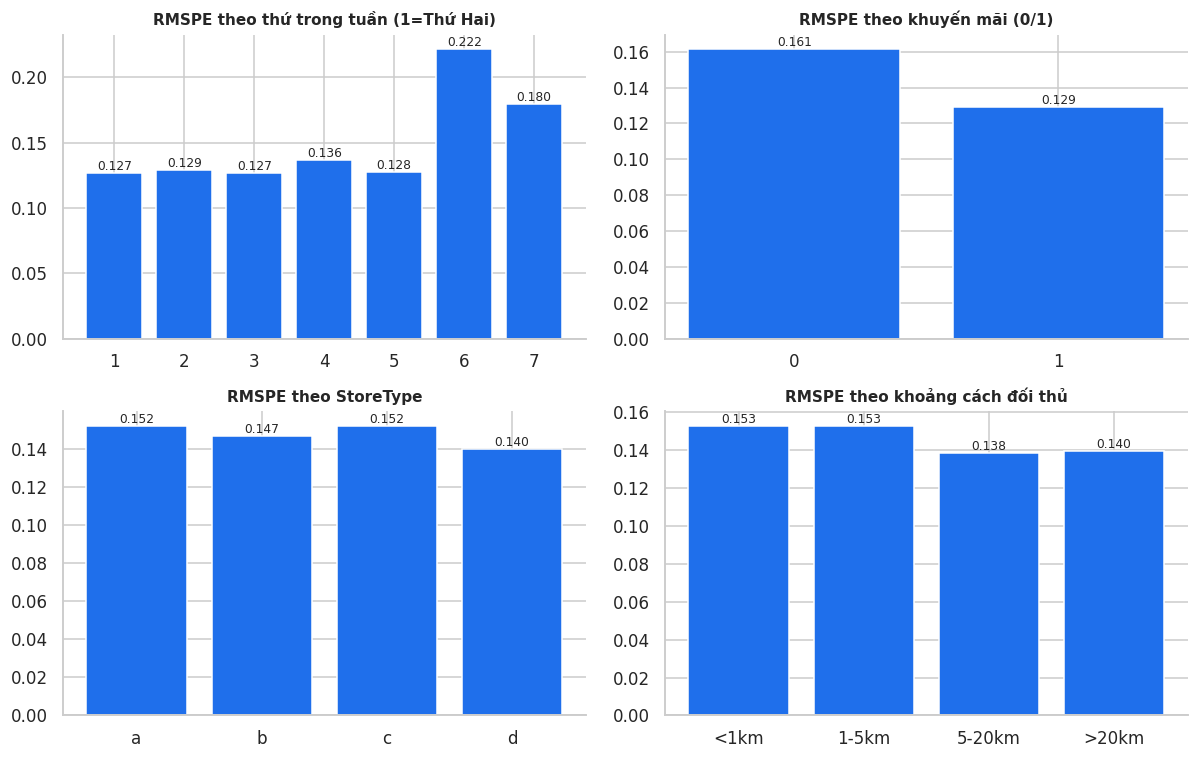

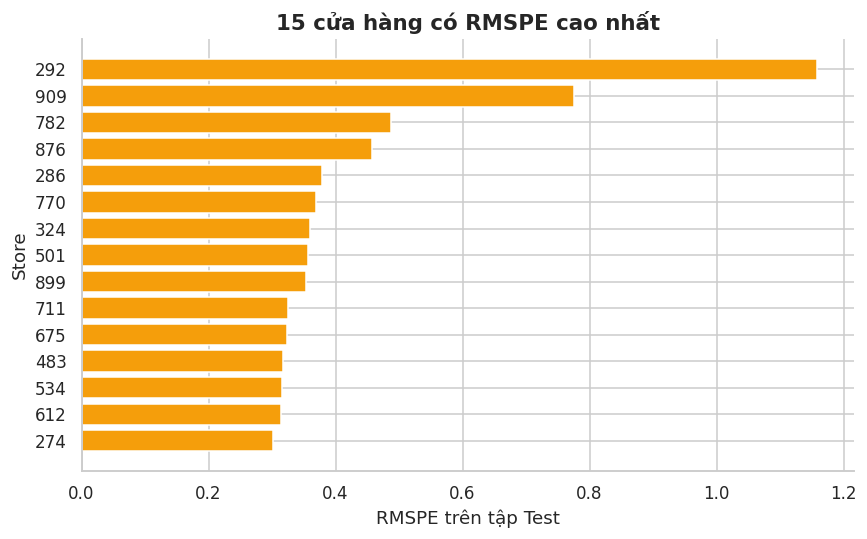

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


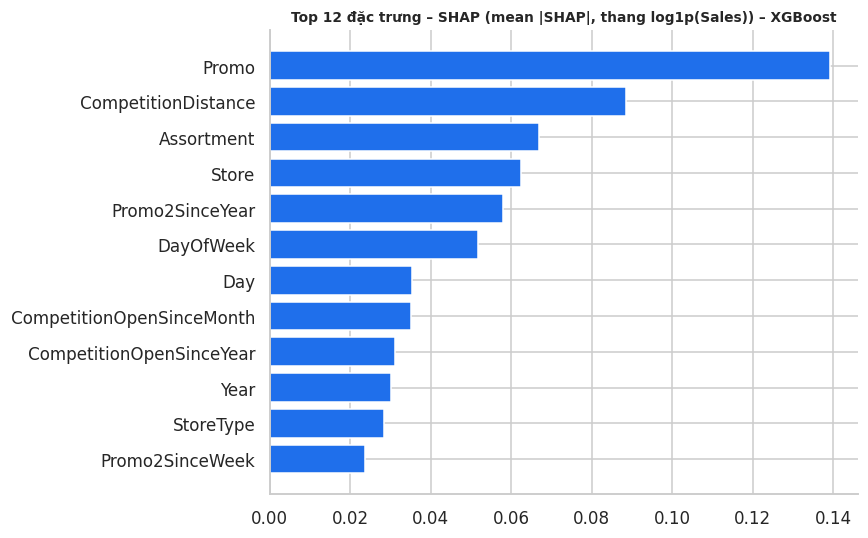

/tmp/ipykernel_2333/2916228924.py:130: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, Xs, feature_names=features, max_display=12, show=False)


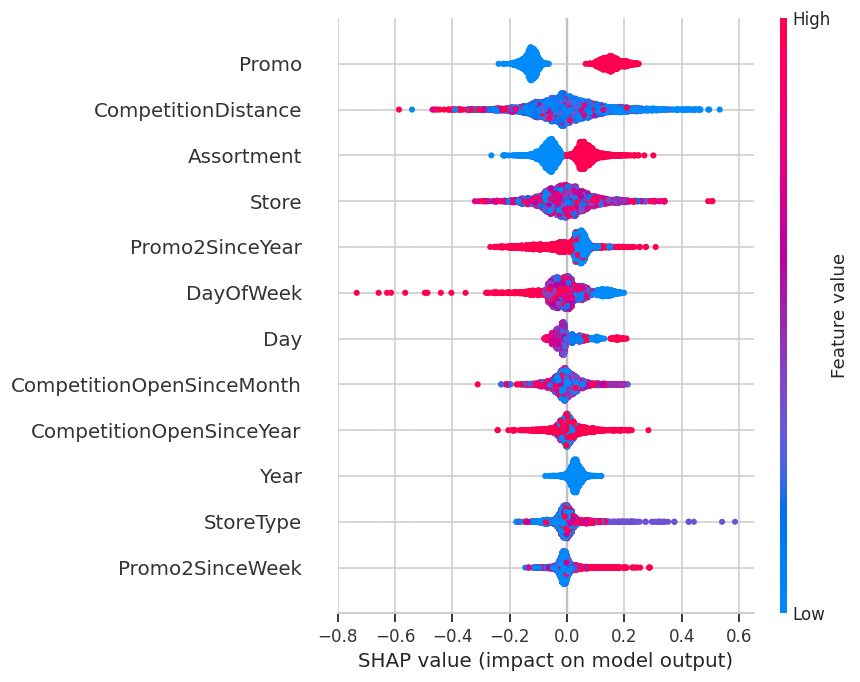

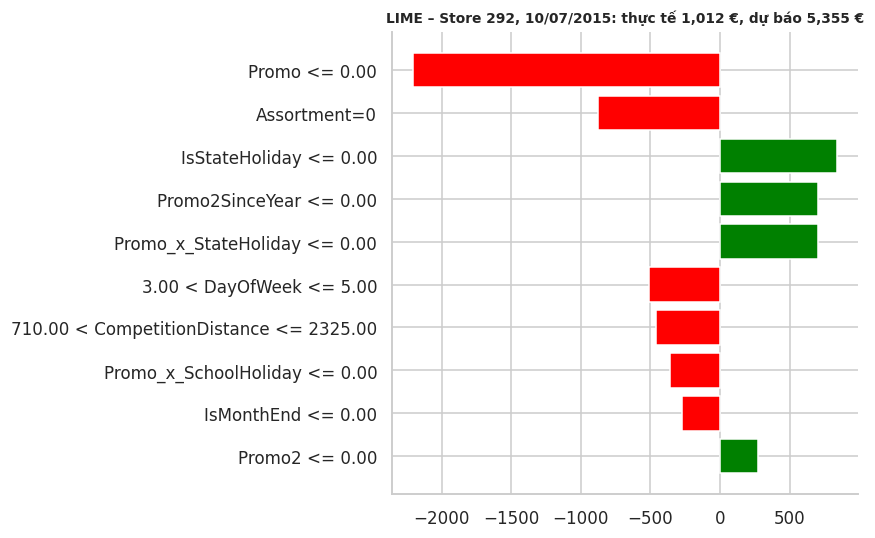

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
import os, json, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

OUT = '/content/outputs'
for sub in ['results', 'figures', 'dashboard']:
    os.makedirs(f'{OUT}/{sub}', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
C_BLUE, C_TEAL, C_AMBER = '#1f6feb', '#12b5a6', '#f59e0b'

# Gom dự báo của mọi mô hình (val, test) – lấy từ các biến đã tạo ở ô trước
preds = {
    'Baseline A (Store-DOW-Promo)': None,   # chỉ có metric, dự báo tính lại bên dưới
    'Baseline B (Seasonal Naive)': None,
    'LightGBM': (lgb_val_preds, lgb_test_preds),
    'XGBoost': (xgb_val_preds, xgb_test_preds),
    'Random Forest': (rf_val_preds, rf_test_preds),
}
models_only = ['LightGBM', 'XGBoost', 'Random Forest']

# Bảng 2: lưu file kết quả (số liệu truy được tới file)
comparison_df.to_csv(f'{OUT}/results/model_comparison.csv', index=False, encoding='utf-8-sig')
display(comparison_df.round(4).style.highlight_min(
    subset=['Val RMSPE', 'Test RMSPE', 'Test MAE', 'Test RMSE'], color='lightgreen'))

# Mô hình tốt nhất = Test RMSPE thấp nhất trong 3 mô hình học máy
best_name = (comparison_df[comparison_df['Mô hình'].isin(models_only)]
             .sort_values('Test RMSPE').iloc[0]['Mô hình'])
best_model = {'LightGBM': lgbm_model, 'XGBoost': xgb_reg, 'Random Forest': rf_reg}[best_name]
best_test_pred = preds[best_name][1]
print('>> Mô hình tốt nhất:', best_name)

# Hình 1: RMSPE Val vs Test
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
labels = comparison_df['Mô hình'].str.replace(' (', '\n(', regex=False)
for a, col in zip(ax, ['Val RMSPE', 'Test RMSPE']):
    a.bar(range(len(comparison_df)), comparison_df[col],
          color=['#9aa5b1', '#c3cad2', C_BLUE, C_TEAL, C_AMBER][:len(comparison_df)])
    a.set_xticks(range(len(comparison_df))); a.set_xticklabels(labels, fontsize=7.5); a.set_title(col)
    for i, v in enumerate(comparison_df[col]):
        a.text(i, v, f'{v:.3f}', ha='center', va='bottom', fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT}/figures/fig1_model_comparison_rmspe.png'); plt.show()

# ===================== CELL 2: C3 – BIỂU ĐỒ + PHÂN TÍCH LỖI (Hình 2–5, Bảng 3–5) =====================
res = test_split[['Store', 'Date', 'DayOfWeek', 'Promo', 'StoreType', 'Assortment',
                  'CompetitionDistance', 'Sales']].copy()
res['Pred'] = best_test_pred
res['Err'] = res['Pred'] - res['Sales']
res['AbsErr'] = res['Err'].abs()
res['PctErr'] = res['Err'] / res['Sales']
res['CompBin'] = pd.cut(res['CompetitionDistance'], [0, 1000, 5000, 20000, np.inf],
                        labels=['<1km', '1-5km', '5-20km', '>20km'])
res.to_csv(f'{OUT}/results/predictions_test_best_model.csv', index=False)

# Hình 2: tổng doanh thu theo ngày – thực tế vs dự báo
dd = res.groupby('Date')[['Sales', 'Pred']].sum() / 1e6
fig, a = plt.subplots(figsize=(10, 4))
a.plot(dd.index, dd['Sales'], color=C_BLUE, marker='o', ms=3, label='Thực tế')
a.plot(dd.index, dd['Pred'], color=C_TEAL, marker='o', ms=3, label='Dự báo')
a.set_ylabel('Tổng doanh thu / ngày (triệu €)'); a.legend()
a.set_title(f'Thực tế vs dự báo, tập Test – {best_name}', fontsize=10)
fig.autofmt_xdate(); plt.tight_layout()
plt.savefig(f'{OUT}/figures/fig2_actual_vs_predicted_daily.png'); plt.show()

# Hình 3: phân phối sai số + scatter
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].hist(res['PctErr'].clip(-0.6, 0.6) * 100, bins=80, color=C_BLUE); ax[0].axvline(0, color='k', lw=.8)
ax[0].set_xlabel('Sai số tương đối (%), cắt ±60%'); ax[0].set_ylabel('Số quan sát')
ax[0].set_title('Phân phối sai số tương đối')
s = res.sample(min(20000, len(res)), random_state=SEED)
ax[1].scatter(s['Sales'], s['Pred'], s=3, alpha=.25, color=C_TEAL)
mx = max(s['Sales'].max(), s['Pred'].max()); ax[1].plot([0, mx], [0, mx], 'k--', lw=.8)
ax[1].set_xlabel('Thực tế (€)'); ax[1].set_ylabel('Dự báo (€)'); ax[1].set_title('Thực tế vs dự báo (mẫu 20.000)')
plt.tight_layout(); plt.savefig(f'{OUT}/figures/fig3_error_distribution.png'); plt.show()

# Bảng 3–5: lỗi theo nhóm (lưu CSV)
def seg(x):
    return pd.Series({'n': len(x), 'RMSPE': rmspe(x['Sales'], x['Pred']),
                      'MAE': x['AbsErr'].mean(), 'Bias_%': 100 * x['PctErr'].mean()})
def by(col):
    g = res.groupby(col, observed=True).apply(seg).reset_index()
    g.to_csv(f'{OUT}/results/error_by_{col}.csv', index=False); return g
e_dow, e_promo, e_type, e_asm, e_comp = by('DayOfWeek'), by('Promo'), by('StoreType'), by('Assortment'), by('CompBin')
e_store = (res.groupby('Store').apply(lambda x: pd.concat([seg(x), pd.Series({'MeanSales': x['Sales'].mean()})]))
           .reset_index().sort_values('RMSPE', ascending=False))
e_store.to_csv(f'{OUT}/results/error_by_Store.csv', index=False)
print('--- Bảng 3: theo thứ trong tuần'); display(e_dow.round(4))
print('--- Bảng 4: theo Promo / StoreType / Assortment / khoảng cách đối thủ')
for g in (e_promo, e_type, e_asm, e_comp): display(g.round(4))
print('--- Bảng 5: 5 cửa hàng RMSPE cao nhất'); display(e_store.head(5).round(3))
sq = res['PctErr'] ** 2
print(f"Bias tổng: {100*res['PctErr'].mean():+.2f}% | Quan sát sai số >10%: {(res['PctErr'].abs()>0.10).mean():.1%} | "
      f"Top-10 cửa hàng chiếm {sq[res['Store'].isin(e_store.head(10)['Store'])].sum()/sq.sum():.1%} tổng bình phương sai số")

# Hình 4: RMSPE theo nhóm
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for a, (g, col, t) in zip(ax.ravel(), [(e_dow, 'DayOfWeek', 'thứ trong tuần (1=Thứ Hai)'), (e_promo, 'Promo', 'khuyến mãi (0/1)'),
                                       (e_type, 'StoreType', 'StoreType'), (e_comp, 'CompBin', 'khoảng cách đối thủ')]):
    a.bar(g[col].astype(str), g['RMSPE'], color=C_BLUE); a.set_title(f'RMSPE theo {t}', fontsize=10)
    for i, v in enumerate(g['RMSPE']): a.text(i, v, f'{v:.3f}', ha='center', va='bottom', fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT}/figures/fig4_error_by_segment.png'); plt.show()

# Hình 5: 15 cửa hàng sai số cao nhất
w = e_store.head(15).iloc[::-1]
fig, a = plt.subplots(figsize=(8, 5))
a.barh(w['Store'].astype(int).astype(str), w['RMSPE'], color=C_AMBER)
a.set_xlabel('RMSPE trên tập Test'); a.set_ylabel('Store'); a.set_title('15 cửa hàng có RMSPE cao nhất')
plt.tight_layout(); plt.savefig(f'{OUT}/figures/fig5_worst_stores.png'); plt.show()

# ===================== CELL 3: C3 – GIẢI THÍCH MÔ HÌNH SHAP + LIME (Hình 6–7) =====================
%pip install -q shap lime
import shap

Xs = X_val.sample(min(5000, len(X_val)), random_state=SEED)       # mẫu để tính SHAP
explainer = shap.TreeExplainer(best_model)
sv = explainer.shap_values(Xs)
sv = np.asarray(sv)

# Hình 6: SHAP – tầm quan trọng toàn cục (mean |SHAP|)
imp = pd.Series(np.abs(sv).mean(0), index=features).sort_values()
imp.sort_values(ascending=False).to_csv(f'{OUT}/results/feature_importance_shap.csv', header=['mean_abs_shap'], index_label='feature')
fig, a = plt.subplots(figsize=(8, 5))
a.barh(imp.tail(12).index, imp.tail(12).values, color=C_BLUE)
a.set_title(f'Top 12 đặc trưng – SHAP (mean |SHAP|, thang log1p(Sales)) – {best_name}', fontsize=9)
plt.tight_layout(); plt.savefig(f'{OUT}/figures/fig6_feature_importance.png'); plt.show()

# Hình 7: SHAP – dạng beeswarm (hướng tác động của đặc trưng)
plt.figure(figsize=(9, 6))
shap.summary_plot(sv, Xs, feature_names=features, max_display=12, show=False)
plt.tight_layout(); plt.savefig(f'{OUT}/figures/fig7_shap_summary.png'); plt.show()

# LIME – giải thích 1 quan sát có sai số lớn nhất (Hình 9)
try:
    from lime.lime_tabular import LimeTabularExplainer
    cat_idx = [features.index(c) for c in categorical_cols]
    lime_exp = LimeTabularExplainer(X_train.sample(20000, random_state=SEED).values, feature_names=features,
                                    categorical_features=cat_idx, mode='regression', random_state=SEED)
    worst = res.assign(a=res['PctErr'].abs()).sort_values('a', ascending=False).index[0]
    pos = test_split.index.get_loc(worst)
    pred_fn = lambda a: np.expm1(best_model.predict(pd.DataFrame(a, columns=features)))
    ex = lime_exp.explain_instance(X_test.iloc[pos].values, pred_fn, num_features=10)
    fig = ex.as_pyplot_figure(); fig.set_size_inches(8, 5)
    plt.title(f"LIME – Store {int(res.loc[worst,'Store'])}, {res.loc[worst,'Date']:%d/%m/%Y}: thực tế {res.loc[worst,'Sales']:,.0f} €, dự báo {res.loc[worst,'Pred']:,.0f} €", fontsize=9)
    plt.tight_layout(); plt.savefig(f'{OUT}/figures/fig9_lime_worst_case.png'); plt.show()
except Exception as e:
    print('LIME bỏ qua:', e)

# ===================== CELL 4: D4 – DASHBOARD (Hình 8) + ĐÓNG GÓI =====================
from IPython.display import HTML, display

hist = val_split.groupby('Date')['Sales'].sum()
fc = res.groupby('Date')['Pred'].sum(); act = res.groupby('Date')['Sales'].sum()
rm = float(comparison_df.loc[comparison_df['Mô hình'] == best_name, 'Test RMSPE'].iloc[0])
by_store = res.groupby('Store').agg(Fc=('Pred', 'sum')).sort_values('Fc', ascending=False)
dow_t = e_dow[e_dow['n'] > 1000]
promo_m = res.groupby('Promo').agg(Fc=('Pred', 'mean'))
M = lambda v: f'{v/1e6:,.2f} triệu €'
tot_h, tot_f, tot_a = hist.sum(), fc.sum(), act.sum(); days = res['Date'].nunique()
uplift = (promo_m.Fc[1] / promo_m.Fc[0] - 1) * 100
dn = {1: 'T2', 2: 'T3', 3: 'T4', 4: 'T5', 5: 'T6', 6: 'T7'}

def line_chart(W=760, H=250):
    mx = pd.concat([hist, fc, act]).max() / 1e6 * 1.08
    dates = list(hist.index) + list(fc.index); pos_ = {x: i for i, x in enumerate(dates)}
    X = lambda x: 50 + pos_[x] / (len(dates) - 1) * (W - 70); Y = lambda v: 20 + (1 - v / 1e6 / mx) * (H - 55)
    P = lambda s: ' '.join(('M' if i == 0 else 'L') + f'{X(x):.1f},{Y(v):.1f}' for i, (x, v) in enumerate(s.items()))
    grid = ''.join(f'<line x1="50" x2="{W-20}" y1="{Y(v*1e6):.1f}" y2="{Y(v*1e6):.1f}" stroke="#e3e9f2"/><text x="44" y="{Y(v*1e6)+4:.1f}" text-anchor="end" font-size="10" fill="#64748b">{v}</text>' for v in range(0, int(mx) + 1, 2))
    lab = ''.join(f'<text x="{X(x):.1f}" y="{H-8}" text-anchor="middle" font-size="10" fill="#64748b">{x:%d/%m}</text>' for x in dates[::7])
    sp = X(fc.index[0])
    return (f'<svg viewBox="0 0 {W} {H}" width="100%">{grid}{lab}<line x1="{sp:.1f}" x2="{sp:.1f}" y1="14" y2="{H-30}" stroke="#94a3b8" stroke-dasharray="4 3"/>'
            f'<text x="{sp+6:.1f}" y="24" font-size="10" fill="#0f766e">Dự báo bắt đầu {fc.index[0]:%d/%m/%Y}</text>'
            f'<path d="{P(act)}" fill="none" stroke="#94a3b8" stroke-width="1.5" stroke-dasharray="3 3"/>'
            f'<path d="{P(hist)}" fill="none" stroke="#1f6feb" stroke-width="2"/><path d="{P(fc)}" fill="none" stroke="#12b5a6" stroke-width="2"/></svg>')
def hbars(items, W=420, rh=26):
    mx = max(v for _, v in items); H = rh * len(items) + 6
    return f'<svg viewBox="0 0 {W} {H}" width="100%">' + ''.join(
        f'<text x="0" y="{i*rh+16}" font-size="11" fill="#334155">{n}</text><rect x="70" y="{i*rh+5}" width="{(W-150)*v/mx:.1f}" height="14" rx="3" fill="#12b5a6"/>'
        f'<text x="{70+(W-150)*v/mx+6:.1f}" y="{i*rh+16}" font-size="11" fill="#334155">{v/1e3:,.0f}k €</text>' for i, (n, v) in enumerate(items)) + '</svg>'
def vbars(items, W=420, H=190):
    mx = max(v for _, v in items) * 1.15; bw = (W - 40) / len(items)
    return f'<svg viewBox="0 0 {W} {H}" width="100%">' + ''.join(
        f'<rect x="{30+i*bw+8:.1f}" y="{10+(H-45)*(1-v/mx):.1f}" width="{bw-16:.1f}" height="{(H-45)*v/mx:.1f}" rx="3" fill="#f59e0b"/>'
        f'<text x="{30+i*bw+bw/2:.1f}" y="{6+(H-45)*(1-v/mx):.1f}" text-anchor="middle" font-size="10" fill="#334155">{v:.1%}</text>'
        f'<text x="{30+i*bw+bw/2:.1f}" y="{H-12}" text-anchor="middle" font-size="11" fill="#334155">{n}</text>' for i, (n, v) in enumerate(items)) + '</svg>'

top = [(f'Store {int(s)}', r.Fc) for s, r in by_store.head(10).iterrows()]
wd = dow_t.loc[dow_t['RMSPE'].idxmax()]
html = f'''<!doctype html><html lang="vi"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Store Revenue – Business Dashboard</title><style>
:root{{--bg:#f4f7fb;--card:#fff;--ink:#0f2447;--mut:#64748b;--line:#e3e9f2}}*{{box-sizing:border-box}}
body{{margin:0;font-family:Inter,Segoe UI,Arial,sans-serif;background:var(--bg);color:var(--ink);display:flex;min-height:100vh}}
aside{{width:210px;background:#0f2e57;color:#cfe0f5;padding:22px 14px;flex-shrink:0}}aside h2{{color:#fff;margin:0 0 2px;font-size:19px}}aside small{{font-size:11px}}
aside nav div{{padding:9px 12px;border-radius:7px;margin-top:6px;font-size:14px}}aside nav .on{{background:#1a64d8;color:#fff}}
main{{flex:1;padding:24px 28px;max-width:1180px}}h1{{margin:0;font-size:26px}}.sub{{color:var(--mut);font-size:14px;margin:4px 0 18px}}
.kpis{{display:grid;grid-template-columns:repeat(4,1fr);gap:14px}}.card{{background:var(--card);border:1px solid var(--line);border-radius:10px;padding:16px 18px}}
.kpi .t{{font-size:13px;color:var(--mut)}}.kpi .v{{font-size:22px;font-weight:700;margin:8px 0 4px}}.kpi .n{{font-size:12px;color:var(--mut)}}
.row{{display:grid;gap:14px;margin-top:14px;grid-template-columns:1fr 1fr}}h3{{margin:0 0 4px;font-size:16px}}.cap{{font-size:12px;color:var(--mut);margin:2px 0 8px}}
.leg span{{font-size:12px;margin-right:14px}}.leg i{{display:inline-block;width:14px;height:3px;vertical-align:middle;margin-right:5px}}
.ins p{{margin:8px 0;font-size:13.5px;line-height:1.45}}.ins b{{display:block;font-size:14px}}.foot{{margin-top:14px;font-size:12px;color:#1e40af;background:#eaf2ff;border-radius:8px;padding:10px 14px}}
@media(max-width:900px){{.kpis{{grid-template-columns:1fr 1fr}}.row{{grid-template-columns:1fr}}aside{{display:none}}}}</style></head><body>
<aside><h2>Store Revenue</h2><small>Forecast &amp; Planning Studio</small><nav style="margin-top:22px"><div>Data Input</div><div>Forecast Results</div><div class="on">Dashboard</div></nav></aside>
<main><h1>Business Dashboard</h1><p class="sub">Doanh thu lịch sử và dự báo theo cửa hàng — dữ liệu Rossmann, mô hình {best_name}.</p>
<div class="kpis">
<div class="card kpi"><div class="t">Historical Sales</div><div class="v">{M(tot_h)}</div><div class="n">{hist.index.min():%d/%m}–{hist.index.max():%d/%m/%Y} (tập validation)</div></div>
<div class="card kpi"><div class="t">Forecast Sales</div><div class="v">{M(tot_f)}</div><div class="n">Thực tế cùng kỳ {M(tot_a)} · lệch {100*(tot_f/tot_a-1):+.1f}%</div></div>
<div class="card kpi"><div class="t">Average Daily Sales</div><div class="v">{res['Pred'].mean():,.0f} €</div><div class="n">Dự báo / cửa hàng / ngày mở cửa</div></div>
<div class="card kpi"><div class="t">Forecast Period</div><div class="v">{days} ngày (~6 tuần)</div><div class="n">{fc.index.min():%d/%m}–{fc.index.max():%d/%m/%Y} · Test RMSPE {rm:.3f}</div></div></div>
<div class="card" style="margin-top:14px"><h3>Sales Overview</h3><div class="cap">Tổng doanh thu mọi cửa hàng theo ngày (triệu €). Chủ Nhật gần như đóng cửa nên đường xuống thấp.</div>
<div class="leg"><span><i style="background:#1f6feb"></i>Historical Sales</span><span><i style="background:#12b5a6"></i>Forecast</span><span><i style="background:#94a3b8"></i>Thực tế (đối chiếu)</span></div>{line_chart()}</div>
<div class="row"><div class="card"><h3>Sales by Store – Top 10 dự báo</h3><div class="cap">Tổng doanh thu dự báo {days} ngày (nghìn €)</div>{hbars(top)}</div>
<div class="card"><h3>Độ tin cậy dự báo theo thứ trong tuần</h3><div class="cap">RMSPE trên tập Test — càng thấp càng chính xác</div>{vbars([(dn[int(r.DayOfWeek)], r.RMSPE) for _, r in dow_t.iterrows()])}</div></div>
<div class="card ins" style="margin-top:14px"><h3>Business Insights</h3>
<p><b>Revenue Outlook</b>Dự báo {M(tot_f)} cho {days} ngày, lệch {100*(tot_f/tot_a-1):+.1f}% so với doanh thu thực tế cùng kỳ.</p>
<p><b>Khuyến mãi</b>Ngày có Promo được dự báo cao hơn {uplift:.0f}% doanh thu trung bình/cửa hàng so với ngày không Promo ({promo_m.Fc[1]:,.0f} € so với {promo_m.Fc[0]:,.0f} €).</p>
<p><b>Planning Considerations</b>Thứ {int(wd.DayOfWeek)+1 if wd.DayOfWeek<7 else 'CN'} là ngày dự báo kém tin cậy nhất (RMSPE {wd.RMSPE:.3f}); nên dự phòng tồn kho/nhân sự và kiểm tra thủ công nhóm cửa hàng sai số cao (error_by_Store.csv).</p></div>
<div class="foot">Daily Sales per store · supervised regression. Khi Open = 0, Sales dự báo = 0.</div></main></body></html>'''
open(f'{OUT}/dashboard/dashboard.html', 'w', encoding='utf-8').write(html)
pd.DataFrame({'date': fc.index, 'forecast': fc.values, 'actual': act.values}).to_csv(f'{OUT}/dashboard/dashboard_data.csv', index=False)
display(HTML(html))                       # Hình 8: chụp màn hình ô này để đưa vào báo cáo

# Đóng gói và tải về
json.dump({'best_model': best_name, 'seed': SEED, 'test_rmspe': rm}, open(f'{OUT}/results/run_info.json', 'w'), ensure_ascii=False, indent=1)
with zipfile.ZipFile('/content/rossmann_c3_d4_outputs.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(OUT):
        for f in files: z.write(os.path.join(root, f), os.path.relpath(os.path.join(root, f), OUT))
try:
    from google.colab import files; files.download('/content/rossmann_c3_d4_outputs.zip')
except Exception as e:
    print('Tải thủ công file /content/rossmann_c3_d4_outputs.zip', e)

In [25]:
from google.colab import drive
drive.mount('/content/drive')

!find "/content/drive/Shared drives/ML/TEST DATA.ipynb" 2>/dev/null

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/Shared drives/ML/TEST DATA.ipynb


In [30]:
import sys, os, re, io, json, base64, shutil
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- 0. đường dẫn
IN_NOTEBOOK = "ipykernel" in sys.modules or "google.colab" in sys.modules

if IN_NOTEBOOK:
    from google.colab import drive
    drive.mount('/content/drive')          # nếu đã mount thì chỉ in thông báo, không lỗi
    NB  = "/content/drive/Shared drives/ML/TEST DATA.ipynb"
    OUT = "/content/out"
else:
    NB  = sys.argv[1] if len(sys.argv) > 1 else "TEST_DATA.ipynb"
    OUT = sys.argv[2] if len(sys.argv) > 2 else "out"

if not os.path.isfile(NB):
    raise FileNotFoundError(f"Không thấy notebook: {NB}")

KQ, HINH = os.path.join(OUT, "ket_qua"), os.path.join(OUT, "hinh")
os.makedirs(KQ, exist_ok=True)
os.makedirs(HINH, exist_ok=True)

nb = json.load(open(NB, encoding="utf-8"))


def tables_in(cell):
    """Trả về list DataFrame lấy từ các output HTML (Styler/DataFrame) của 1 ô."""
    res = []
    for o in cell.get("outputs", []):
        d = o.get("data", {})
        if "text/html" in d and "<table" in "".join(d["text/html"]):
            h = "".join(d["text/html"])
            t = pd.read_html(io.StringIO(h))[0]
            if str(t.columns[0]).startswith("Unnamed"):
                t = t.drop(columns=t.columns[0])
            res.append(t)
    return res


# ---------------------------------------------------------------- 1. bảng kết quả
comparison, seg_tables, top_store = None, {}, None
for ci, c in enumerate(nb["cells"]):
    if c["cell_type"] != "code":
        continue
    for t in tables_in(c):
        cols = list(t.columns)
        if "Val RMSPE" in cols:
            if comparison is None:
                comparison = t.copy()
        elif "MeanSales" in cols:
            top_store = t.copy()
        else:
            for key in ["DayOfWeek", "Promo", "StoreType", "Assortment", "CompBin"]:
                if cols[0] == key and "RMSPE" in cols:
                    seg_tables[key] = t.copy()

assert comparison is not None, "Không thấy bảng so sánh mô hình trong output của notebook (hãy chạy xong và lưu notebook)"
comparison.to_csv(f"{KQ}/model_comparison.csv", index=False, encoding="utf-8-sig")
for k, t in seg_tables.items():
    t.to_csv(f"{KQ}/error_by_{k}.csv", index=False)
if top_store is not None:
    top_store.to_csv(f"{KQ}/error_by_Store_top5.csv", index=False)

# số tổng hợp (Bias, >10%, top-10) nằm trong output dạng text
summ = {}
for c in nb["cells"]:
    for o in c.get("outputs", []):
        if o.get("output_type") == "stream":
            txt = "".join(o["text"])
            m = re.search(r"Bias tổng: ([+\-][\d.]+)% \| Quan sát sai số >10%: ([\d.]+)% \| Top-10 cửa hàng chiếm ([\d.]+)%", txt)
            if m:
                summ.update({"bias_total_pct": float(m.group(1)),
                             "share_abs_err_gt10_pct": float(m.group(2)),
                             "top10_store_share_sq_err_pct": float(m.group(3))})
            m = re.search(r"Mô hình tốt nhất: (.+)", txt)
            if m:
                summ["best_model"] = m.group(1).strip()
            m = re.search(r"Tập Train: \((\d+), (\d+)\)\s+Tập Validation: \((\d+), \d+\)\s+Tập Test: \((\d+), \d+\)", txt)
            if m:
                summ.update(n_train=int(m.group(1)), n_features=int(m.group(2)),
                            n_val=int(m.group(3)), n_test=int(m.group(4)))
json.dump(summ, open(f"{KQ}/run_summary.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

# ---------------------------------------------------------------- 2. tách hình PNG + dashboard HTML
dash_html = None
n_img = 0
for ci, c in enumerate(nb["cells"]):
    if c["cell_type"] != "code":
        continue
    k = 0
    for o in c.get("outputs", []):
        d = o.get("data", {})
        if "image/png" in d and ci >= 25:
            k += 1
            n_img += 1
            open(f"{HINH}/nb_c{ci}_{k:02d}.png", "wb").write(base64.b64decode(d["image/png"]))
        if "text/html" in d:
            h = "".join(d["text/html"])
            if "Business Dashboard" in h and "<svg" in h:
                dash_html = h

# đặt tên theo số hình trong Chương 4 (thứ tự hình xuất ra ở ô 25 của notebook)
NAMES = ["hinh4_1_so_sanh_RMSPE", "hinh4_3_thuc_te_vs_du_bao", "hinh4_4_phan_phoi_sai_so",
         "hinh4_5_RMSPE_theo_nhom", "hinh4_7_top15_cua_hang_sai_so", "hinh4_8_SHAP_tam_quan_trong",
         "hinh4_9_SHAP_beeswarm", "hinh4_10_LIME_store292"]
for i, nm in enumerate(NAMES, 1):
    src = f"{HINH}/nb_c25_{i:02d}.png"
    if os.path.exists(src):
        shutil.copy(src, f"{HINH}/{nm}.png")
print(f"Đã tách {n_img} hình từ notebook")

if dash_html:
    open(f"{KQ}/dashboard.html", "w", encoding="utf-8").write(dash_html)
    # KPI trên dashboard -> JSON để đối chiếu
    txt = re.sub(r"<style.*?</style>", "", dash_html, flags=re.S)
    txt = re.sub(r"<[^>]+>", " ", txt)
    txt = re.sub(r"\s+", " ", txt)
    kpi = {}
    pats = {
        "historical_sales_musd": r"Historical Sales ([\d.,]+) triệu €",
        "forecast_sales_musd": r"Forecast Sales ([\d.,]+) triệu €",
        "actual_sales_musd": r"Thực tế cùng kỳ ([\d.,]+) triệu €",
        "gap_pct": r"lệch ([+\-−][\d.]+)%",
        "avg_daily_sales_eur": r"Average Daily Sales ([\d.,]+) €",
        "forecast_days": r"Forecast Period (\d+) ngày",
        "promo_forecast_eur": r"\(([\d.,]+) € so với ([\d.,]+) €\)",
    }
    for k_, p in pats.items():
        m = re.search(p, txt)
        if m:
            kpi[k_] = m.groups() if len(m.groups()) > 1 else m.group(1)
    kpi["top10_stores_k_eur"] = re.findall(r"Store (\d+) (\d+)k €", txt)
    json.dump(kpi, open(f"{KQ}/dashboard_kpi.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    try:
        from playwright.sync_api import sync_playwright
        with sync_playwright() as p:
            b = p.chromium.launch()
            pg = b.new_page(viewport={"width": 1360, "height": 900}, device_scale_factor=1.5)
            pg.set_content(dash_html, wait_until="load")
            pg.screenshot(path=f"{HINH}/hinh4_14_dashboard.png", full_page=True)
            b.close()
        print("Đã chụp dashboard -> hinh4_14_dashboard.png")
    except Exception as e:  # không có playwright: chụp tay ô cuối của notebook
        print("Bỏ qua chụp dashboard:", e)

# ---------------------------------------------------------------- 3. hình bổ sung
plt.rcParams.update({"figure.dpi": 130, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, TEAL, AMBER, GREY = "#1f6feb", "#12b5a6", "#f59e0b", "#9aa5b1"

cmp_ = comparison.copy()
short = {"Baseline A (Store-DOW-Promo)": "Baseline A", "Baseline B (Seasonal Naive)": "Baseline B"}
cmp_["Tên"] = cmp_["Mô hình"].replace(short)
cols = [GREY, "#c3cad2", BLUE, TEAL, AMBER]

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, col in zip(ax, ["Test MAE", "Test RMSE"]):
    a.bar(range(len(cmp_)), cmp_[col], color=cols[:len(cmp_)])
    a.set_xticks(range(len(cmp_)))
    a.set_xticklabels(cmp_["Tên"], fontsize=8)
    a.set_title(f"{col} (€)", fontweight="bold")
    for i, v in enumerate(cmp_[col]):
        a.text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.savefig(f"{HINH}/hinh4_2_MAE_RMSE_test.png")
plt.close()

# Bias theo nhóm
DOW = {1: "T2", 2: "T3", 3: "T4", 4: "T5", 5: "T6", 6: "T7", 7: "CN"}
groups = [("DayOfWeek", "Thứ trong tuần", lambda x: DOW[int(x)]),
          ("StoreType", "StoreType", str),
          ("Assortment", "Assortment", str),
          ("CompBin", "Khoảng cách đối thủ", str)]
fig, ax = plt.subplots(2, 2, figsize=(11, 6.6))
for a, (k, ttl, f) in zip(ax.ravel(), groups):
    if k not in seg_tables:
        a.set_visible(False)
        print(f"Cảnh báo: không tìm thấy bảng sai số theo {k} trong notebook")
        continue
    t = seg_tables[k]
    vals = t["Bias_%"].values
    a.bar([f(x) for x in t[k]], vals, color=[AMBER if v < 0 else BLUE for v in vals])
    a.axhline(0, color="k", lw=.8)
    a.set_title(f"Bias (%) theo {ttl}", fontsize=10, fontweight="bold")
    for i, v in enumerate(vals):
        a.text(i, v, f"{v:+.2f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=8)
fig.text(0.5, 0.005, "Bias = trung bình (dự báo − thực tế) / thực tế.  Xanh: dự báo cao hơn thực tế; cam: thấp hơn.",
         ha="center", fontsize=8.5)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(f"{HINH}/hinh4_6_bias_theo_nhom.png")
plt.close()

# ---------------------------------------------------------------- 4. bảng kiểm tra
c = cmp_.set_index("Tên")
A, X, L, R = c.loc["Baseline A"], c.loc["XGBoost"], c.loc["LightGBM"], c.loc["Random Forest"]
pct = lambda new, old: 100 * (new - old) / old
chk = {
    "XGB vs Baseline A – Val RMSPE (%)": pct(X["Val RMSPE"], A["Val RMSPE"]),
    "XGB vs Baseline A – Test RMSPE (%)": pct(X["Test RMSPE"], A["Test RMSPE"]),
    "XGB vs Baseline A – Test MAE (%)": pct(X["Test MAE"], A["Test MAE"]),
    "XGB vs Baseline A – Test RMSE (%)": pct(X["Test RMSE"], A["Test RMSE"]),
    "XGB vs LightGBM – Test RMSPE (%)": pct(X["Test RMSPE"], L["Test RMSPE"]),
    "XGB Val->Test RMSPE (điểm)": X["Test RMSPE"] - X["Val RMSPE"],
    "LightGBM Val->Test RMSPE (điểm)": L["Test RMSPE"] - L["Val RMSPE"],
    "Baseline A Val->Test RMSPE (điểm)": A["Test RMSPE"] - A["Val RMSPE"],
    "RF vs XGB – Test RMSPE (%)": pct(R["Test RMSPE"], X["Test RMSPE"]),
    "Top-10 cửa hàng: tỷ lệ so với phân bổ đều (lần)":
        summ.get("top10_store_share_sq_err_pct", np.nan) / (100 * 10 / 1115),
}
pd.Series(chk).round(4).to_csv(f"{KQ}/kiem_tra_so_lieu.csv", header=["gia_tri"],
                               index_label="chi_tieu", encoding="utf-8-sig")
print("\n=== KIỂM TRA SỐ LIỆU ===")
for k, v in chk.items():
    print(f"{k:55s} {v:+.4f}")
print("\nTóm tắt:", summ)
print(f"\nKết quả nằm trong: {OUT}")

import shutil
shutil.copytree("/content/out", "/content/drive/MyDrive/out", dirs_exist_ok=True)
print("Đã lưu vào: My Drive/out")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Đã tách 8 hình từ notebook
Bỏ qua chụp dashboard: No module named 'playwright'

=== KIỂM TRA SỐ LIỆU ===
XGB vs Baseline A – Val RMSPE (%)                       -8.3389
XGB vs Baseline A – Test RMSPE (%)                      +0.6562
XGB vs Baseline A – Test MAE (%)                        -4.2464
XGB vs Baseline A – Test RMSE (%)                       -6.5937
XGB vs LightGBM – Test RMSPE (%)                        -6.6048
XGB Val->Test RMSPE (điểm)                              +0.0082
LightGBM Val->Test RMSPE (điểm)                         +0.0124
Baseline A Val->Test RMSPE (điểm)                       -0.0056
RF vs XGB – Test RMSPE (%)                              +43.4460
Top-10 cửa hàng: tỷ lệ so với phân bổ đều (lần)         +9.9235

Tóm tắt: {'n_train': 765470, 'n_features': 24, 'n_val': 37472, 'n_test': 41396, 'best_model': 'XGBoost', 'bias_total_pct': 0